## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. The dataset: `MCU Box Office.zip` is already in `C:\Users\sivan\Datasets` (made from [Kaggle – Marvel Cinematic Universe Box Office Dataset](https://www.kaggle.com/datasets/davidgdong/marvel-cinematic-universe-box-office-dataset)).
3. When the upload cell asks for a file, choose `MCU Box Office.zip` from `C:\Users\sivan\Datasets`.

**Run the cells from top to bottom** (Shift+Enter runs one cell). After a restart, run them again from the top.

# Week 2 Day 4 – Exercises XP Gold: Data Visualization

## 👩‍🏫 👩🏿‍🏫 What You’ll learn
- Advanced visualization techniques with Matplotlib and Seaborn.
- Manipulating and analyzing hierarchical data in pandas.
- Filtering and querying data in complex datasets.
- Exploring relationships and distributions with visualizations.

## Setup
Run this cell first. It imports the libraries used in all the exercises.

In [1]:
import pandas as pd
# pandas: for working with tables (DataFrames)
import numpy as np
# numpy: for math on lists of numbers
import matplotlib.pyplot as plt
# matplotlib: for drawing charts
import seaborn as sns
# seaborn: nicer statistical charts, built on top of matplotlib

---
# Exercise 1: Bar Graph
**Objective:** Bar graph of a retail company’s sales: x = product categories, y = total sales, with labels, a title and colors.

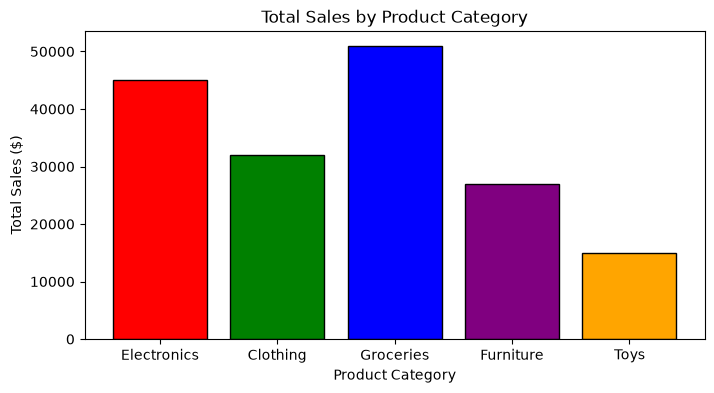

In [2]:
categories = ['Electronics', 'Clothing', 'Groceries', 'Furniture', 'Toys']
# fictional product categories (x axis)
total_sales = [45000, 32000, 51000, 27000, 15000]
# fictional total sales of each category in $ (y axis)
plt.figure(figsize=(8, 4))
# a new chart
plt.bar(categories, total_sales, color=['red', 'green', 'blue', 'purple', 'orange'], edgecolor='black')
# one colored bar per category with a black border
plt.xlabel('Product Category')
# label of the x axis
plt.ylabel('Total Sales ($)')
# label of the y axis
plt.title('Total Sales by Product Category')
# chart title
plt.show()
# show the chart

---
# Exercise 2: Hierarchical Indexing
**Objective:** Find all days when the temperature was above 30°C (86°F) in Canadian cities, using a hierarchical index on ‘Country’, ‘City’, ‘Date’.

In [3]:
data = {
    'Country': ['Canada'] * 6 + ['USA'] * 4,
    'City': ['Toronto', 'Toronto', 'Toronto', 'Montreal', 'Montreal', 'Vancouver', 'New York', 'New York', 'Miami', 'Miami'],
    'Date': ['2024-07-01', '2024-07-02', '2024-07-03', '2024-07-01', '2024-07-02', '2024-07-01', '2024-07-01', '2024-07-02', '2024-07-01', '2024-07-02'],
    'Temperature': [29, 32, 31, 28, 33, 24, 31, 34, 35, 33]
}
# a small made-up dataset: temperature (°C) per country, city and day
df_temp = pd.DataFrame(data)
# make a DataFrame from the dictionary
df_temp = df_temp.set_index(['Country', 'City', 'Date'])
# 3-level (hierarchical) index: Country -> City -> Date
df_temp

Temperature
Country City      Date                   
Canada  Toronto   2024-07-01           29
                  2024-07-02           32
                  2024-07-03           31
        Montreal  2024-07-01           28
                  2024-07-02           33
        Vancouver 2024-07-01           24
USA     New York  2024-07-01           31
                  2024-07-02           34
        Miami     2024-07-01           35
                  2024-07-02           33

In [4]:
canada = df_temp.loc['Canada']
# .loc['Canada'] keeps only the Canada rows (the index now is City -> Date)
hot_days = canada[canada['Temperature'] > 30]
# keep only the days hotter than 30°C
hot_days

Temperature
City     Date                   
Toronto  2024-07-02           32
         2024-07-03           31
Montreal 2024-07-02           33

**How does hierarchical indexing help?**
The index works like folders: Country → City → Date. With one short command (`.loc['Canada']`) we jump straight to the Canada part, and we could go deeper (`.loc[('Canada', 'Toronto')]`) without writing several filters. The data stays grouped in a logical way, so multi-level questions are easier to write and to read.

---
# Exercise 3: Advanced Filtering with Hierarchical Indices
**Objective:** Show the rows where ‘Salary’ is above 50,000 within each ‘Department’.

The XP exercises of today have no employee DataFrame, so we build a small one with a hierarchical index (Department → Employee).

In [5]:
employees = pd.DataFrame({
    'Department': ['HR', 'HR', 'HR', 'IT', 'IT', 'IT', 'Sales', 'Sales', 'Sales'],
    'Employee': ['Anna', 'Ben', 'Carla', 'Dan', 'Eva', 'Fred', 'Gil', 'Hila', 'Ido'],
    'Salary': [42000, 55000, 61000, 72000, 48000, 90000, 39000, 51000, 47000]
})
# a small made-up table of employees and salaries
employees = employees.set_index(['Department', 'Employee'])
# hierarchical index: Department -> Employee
employees

Salary
Department Employee        
HR         Anna       42000
           Ben        55000
           Carla      61000
IT         Dan        72000
           Eva        48000
           Fred       90000
Sales      Gil        39000
           Hila       51000
           Ido        47000

In [6]:
high_salary = employees[employees['Salary'] > 50000]
# keep only salaries above 50,000; the Department level is kept
high_salary

Salary
Department Employee        
HR         Ben        55000
           Carla      61000
IT         Dan        72000
           Fred       90000
Sales      Hila       51000

In [7]:
for dept in high_salary.index.get_level_values('Department').unique():
    # go through each department that has at least one high salary
    print(dept)
    # print the department name
    print(high_salary.loc[dept])
    # .loc[dept] shows only that department's rows
    print()
    # empty line between departments

HR
          Salary
Employee        
Ben        55000
Carla      61000

IT
          Salary
Employee        
Dan        72000
Fred       90000

Sales
          Salary
Employee        
Hila       51000



**Why it helps:** after one filter, the result is still grouped by department, so `.loc['IT']` instantly gives the IT employees above 50,000 – no extra filtering on a 'Department' column is needed.

---
## Load the MCU dataset (Exercises 4–6)
Run the upload cell, then read the CSV. The money columns are text with commas, so we clean them below.

In [ ]:
from google.colab import files
# the Colab tool for uploading files from your computer
uploaded = files.upload()
# choose "MCU Box Office.zip" (saved in a variable so its contents are not printed)
!unzip "MCU Box Office.zip"
# unzip it: you get the file "mcu_box_office.csv"

In [8]:
mcu = pd.read_csv('mcu_box_office.csv')
# read the MCU file into a DataFrame
print(mcu.shape)
# 27 movies, 10 columns
mcu.head()
# first 5 rows

(27, 10)


,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
0,Iron Man,1,5/2/2008,94,91,126,"186,000,000","102,118,668","318,604,126","585,171,547"
1,The Incredible Hulk,1,6/13/2008,67,70,112,"137,500,000","55,414,050","134,806,913","265,573,859"
2,Iron Man 2,1,5/7/2010,72,71,124,"170,000,000","128,122,480","312,433,331","621,156,389"
3,Thor,1,5/6/2011,77,76,113,"150,000,000","65,723,338","181,030,624","449,326,618"
4,Captain America: The First Avenger,1,7/22/2011,79,75,124,"140,000,000","65,058,524","176,654,505","370,569,776"


---
# Exercise 4: Visualizing Movie Durations
**Objective:** Distribution of MCU movie durations with `histplot`, a KDE line and a title.

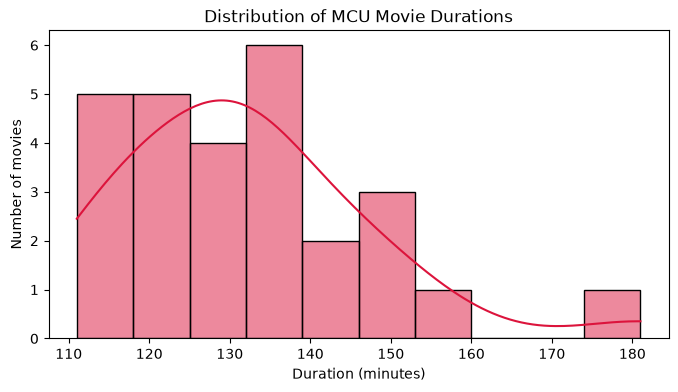

In [9]:
plt.figure(figsize=(8, 4))
# a new chart
sns.histplot(data=mcu, x='movie_duration', bins=10, kde=True, color='crimson')
# histogram of durations; kde=True adds a smooth curve on top
plt.title('Distribution of MCU Movie Durations')
# chart title
plt.xlabel('Duration (minutes)')
# label of the x axis
plt.ylabel('Number of movies')
# label of the y axis
plt.show()
# show the chart

**What we see:** most MCU movies last between about 115 and 140 minutes; *Avengers: Endgame* (181 min) is the long outlier.

---
# Exercise 5: Box Plot of Audience and Tomato Meter Scores
**Objective:** Melt the two scores into a long table and compare them with a box plot.

In [10]:
scores = mcu.melt(id_vars='movie_title', value_vars=['tomato_meter', 'audience_score'], var_name='Score Type', value_name='Score')
# melt: 2 score columns -> 1 column 'Score' + 1 column saying which score it is
scores.head()
# each movie now appears twice: once per score type

,movie_title,Score Type,Score
0,Iron Man,tomato_meter,94
1,The Incredible Hulk,tomato_meter,67
2,Iron Man 2,tomato_meter,72
3,Thor,tomato_meter,77
4,Captain America: The First Avenger,tomato_meter,79


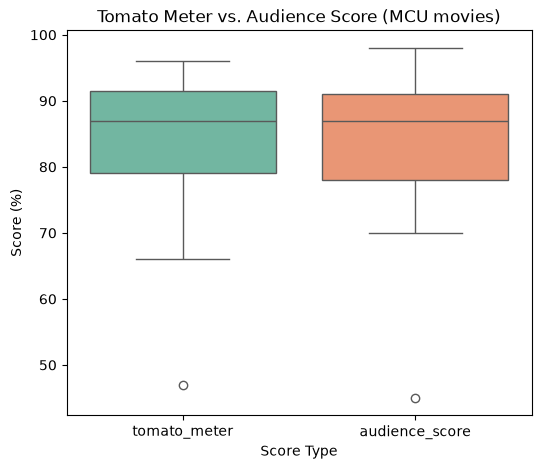

In [11]:
plt.figure(figsize=(6, 5))
# a new chart
sns.boxplot(data=scores, x='Score Type', y='Score', hue='Score Type', palette='Set2', legend=False)
# one box per score type: median line, quartiles box, whiskers and outliers
plt.title('Tomato Meter vs. Audience Score (MCU movies)')
# chart title
plt.ylabel('Score (%)')
# label of the y axis
plt.show()
# show the chart

**What we see:** both scores are mostly high (70–95%). The critics’ Tomato Meter is spread a bit more and has some low outliers.

---
# Exercise 6: Pair Plot of Financial Data
**Objective:** `pairplot` of Production Budget, Opening Weekend, Domestic and Worldwide Box Office, colored by `mcu_phase`.

In [12]:
money_cols = ['production_budget', 'opening_weekend', 'domestic_box_office', 'worldwide_box_office']
# the 4 financial columns
print(mcu[money_cols].dtypes)
# they are text (object) because of the commas, e.g. '186,000,000'

production_budget       str
opening_weekend         str
domestic_box_office     str
worldwide_box_office    str
dtype: object


In [13]:
for col in money_cols:
    # repeat for each financial column
    mcu[col] = mcu[col].str.replace(',', '').astype(float) / 1_000_000
    # remove commas, turn into numbers, and divide by 1 million for easier reading
mcu[money_cols].head()
# now the values are numbers in millions of $

,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
0,186.0,102.118668,318.604126,585.171547
1,137.5,55.414050,134.806913,265.573859
2,170.0,128.122480,312.433331,621.156389
3,150.0,65.723338,181.030624,449.326618
4,140.0,65.058524,176.654505,370.569776


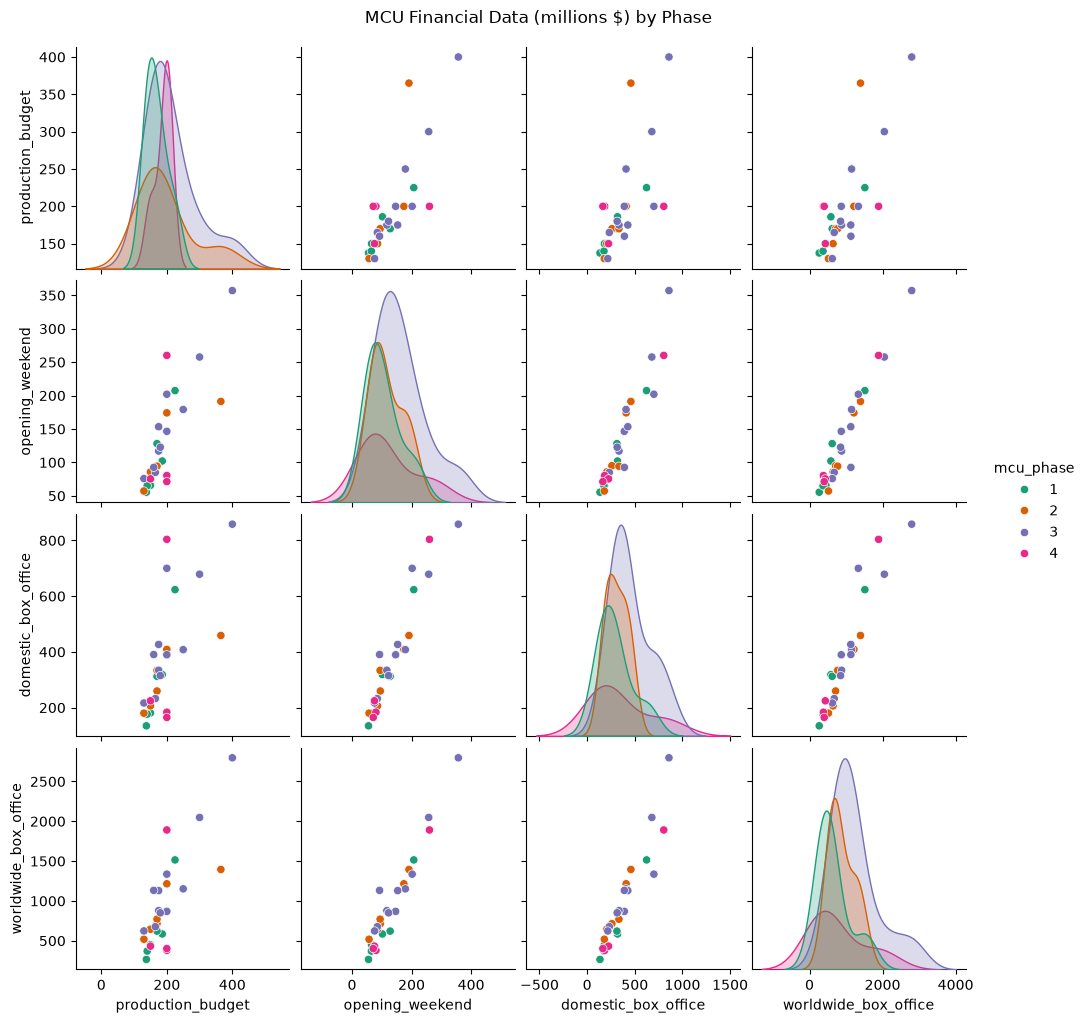

In [14]:
sns.pairplot(mcu, vars=money_cols, hue='mcu_phase', palette='Dark2')
# a grid of scatter plots for every pair of columns, colored by MCU phase
plt.suptitle('MCU Financial Data (millions $) by Phase', y=1.02)
# one title above the whole grid
plt.show()
# show the chart

**What we see:** the four money columns rise together – movies with a big opening weekend also earn more in total. Phase 3 has the biggest budgets and box-office results (the Avengers movies).